## 🌐 **Google Drive Connection**

In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\Drive/Thereluctants/Second Challenge"
%cd $current_dir

Mounted at /gdrive
/gdrive/.shortcut-targets-by-id/1yYKEvtJJc827iWVA8QcJqUxZdjJlv74u/local_TheRelU_ctants


## ⚙️ **Libraries Import**



In [ ]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO
from torchvision.transforms.v2 import AutoAugment, AutoAugmentPolicy


# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cu126
Device: cuda


## ⏳**DATA LOADING**

In [ ]:
IMG_SIZE = 1024

In [ ]:
def load_images_from_folder(folder):
    labels_df = pd.read_csv(os.path.join(os.getcwd(), "train_labels.csv"))
    labels = []
    filepaths = []
    masks_filepaths = [] # New list for mask file paths

    # Iterate through files in the specified folder
    for filename in os.listdir(folder):
        if filename.startswith("mask_"):
            masks_filepaths.append(os.path.join(folder, filename))
            continue

        # Check if the filename exists in the labels_df
        matching_labels = labels_df.loc[labels_df['sample_index'] == filename, 'label']

        if matching_labels.empty:
            print(f"Warning: No label found for {filename}. Skipping this image.")
            continue

        label = matching_labels.values[0]
        labels.append(label)
        filepaths.append(os.path.join(folder, filename))
        print(f"Found filepath for {filename}")

    return filepaths, masks_filepaths, labels # Return both lists

# Load image file paths and labels
img_path = 'train_data_updated'
image_filepaths, masks_filepaths, labels = load_images_from_folder(img_path)
print(f"Loaded {len(image_filepaths)} image filepaths")
print(f"Loaded {len(masks_filepaths)} mask filepaths")
print(f"Loaded {len(labels)} labels")

Found filepath for img_0347.png
Found filepath for img_0301.png
Found filepath for img_0312.png
Found filepath for img_0310.png
Found filepath for img_0323.png
Found filepath for img_0351.png
Found filepath for img_0357.png
Found filepath for img_0331.png
Found filepath for img_0224.png
Found filepath for img_0322.png
Found filepath for img_0299.png
Found filepath for img_0250.png
Found filepath for img_0309.png
Found filepath for img_0315.png
Found filepath for img_0318.png
Found filepath for img_0285.png
Found filepath for img_0243.png
Found filepath for img_0234.png
Found filepath for img_0328.png
Found filepath for img_0362.png
Found filepath for img_0295.png
Found filepath for img_0345.png
Found filepath for img_0266.png
Found filepath for img_0203.png
Found filepath for img_0246.png
Found filepath for img_0242.png
Found filepath for img_0240.png
Found filepath for img_0289.png
Found filepath for img_0303.png
Found filepath for img_0261.png
Found filepath for img_0335.png
Found fi

In [ ]:
label_mapping = {
    'Luminal B': 0,
    'Luminal A': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

# Convert string labels to numerical labels
numerical_labels = [label_mapping[label] for label in labels]

print(f"Original labels (first 5): {labels[:5]}")
print(f"Numerical labels (first 5): {numerical_labels[:5]}")
print(f"Number of numerical labels: {len(numerical_labels)}")


Original labels (first 5): ['Luminal A', 'Luminal A', 'HER2(+)', 'HER2(+)', 'Triple negative']
Numerical labels (first 5): [1, 1, 2, 2, 3]
Number of numerical labels: 581


In [ ]:
import os

# Create a set of valid image base filenames for efficient lookup
# (e.g., 'img_0354.png' from 'train_data_updated/img_0354.png')
valid_image_names = set(os.path.basename(fp) for fp in image_filepaths)

filtered_masks_filepaths = []
initial_mask_count = len(masks_filepaths)

for mask_fp in masks_filepaths:
    mask_basename = os.path.basename(mask_fp)
    # Masks are named like 'mask_0354.png'. We need to check for 'img_0354.png'.
    if mask_basename.startswith("mask_"):
        # Construct the corresponding image filename, e.g., 'img_0354.png' from 'mask_0354.png'
        corresponding_image_name = "img_" + mask_basename[len("mask_"):]
        if corresponding_image_name in valid_image_names:
            filtered_masks_filepaths.append(mask_fp)
    else:
        print(f"Warning: Mask filename '{mask_basename}' does not start with 'mask_'. Skipping.")

# Update masks_filepaths with the filtered list
masks_filepaths = filtered_masks_filepaths

print(f"Original number of mask filepaths loaded: {initial_mask_count}")
print(f"New number of mask filepaths after filtering: {len(masks_filepaths)}")


Original number of mask filepaths loaded: 631
New number of mask filepaths after filtering: 556


In [ ]:
import re
import os

# 1. Create a dictionary to quickly look up mask filepaths by their base filename (e.g., 'mask_0354.png' -> full_path)
# This is crucial because masks_filepaths (from Nl9iM640gU6i) might not be in the same order as image_filepaths.
mask_filepath_lookup = {os.path.basename(fp): fp for fp in masks_filepaths}

# 2. Reconstruct combined_data, ensuring correct pairing for each image, its mask, and its label
combined_data = []
for i, img_path in enumerate(image_filepaths):
    img_basename = os.path.basename(img_path) # e.g., 'img_0354.png'

    # Extract numerical ID from image filename
    match = re.search(r'img_(\d+)\.png', img_basename)
    if not match:
        print(f"Warning: Could not extract numerical ID from image path: {img_path}. Skipping.")
        continue

    img_id = int(match.group(1))

    # Construct the expected mask filename (e.g., 'mask_0354.png')
    expected_mask_basename = img_basename.replace("img_", "mask_")

    # Check if this expected mask actually exists in our filtered masks
    if expected_mask_basename in mask_filepath_lookup:
        corresponding_mask_path = mask_filepath_lookup[expected_mask_basename]
        combined_data.append((img_id, img_path, corresponding_mask_path, numerical_labels[i]))
    else:
        print(f"Warning: No corresponding mask file ({expected_mask_basename}) found for image {img_path}. Skipping.")

# Sort the combined data based on the numerical ID
combined_data.sort(key=lambda x: x[0])

# Unpack the sorted data back into separate lists
image_filepaths_sorted = [item[1] for item in combined_data]
masks_filepaths_sorted = [item[2] for item in combined_data]
numerical_labels_sorted = [item[3] for item in combined_data]

# Update the original lists with the sorted versions
image_filepaths = image_filepaths_sorted
masks_filepaths = masks_filepaths_sorted
numerical_labels = numerical_labels_sorted

print(f"Data sorted by numerical order of image filenames.")
print(f"First 5 sorted image filepaths: {image_filepaths[:5]}")
print(f"First 5 sorted mask filepaths: {masks_filepaths[:5]}")
print(f"First 5 sorted numerical labels: {numerical_labels[:5]}")

Data sorted by numerical order of image filenames.
First 5 sorted image filepaths: ['train_data_updated/img_0000.png', 'train_data_updated/img_0002.png', 'train_data_updated/img_0003.png', 'train_data_updated/img_0004.png', 'train_data_updated/img_0006.png']
First 5 sorted mask filepaths: ['train_data_updated/mask_0000.png', 'train_data_updated/mask_0002.png', 'train_data_updated/mask_0003.png', 'train_data_updated/mask_0004.png', 'train_data_updated/mask_0006.png']
First 5 sorted numerical labels: [3, 0, 0, 0, 1]


**Show some images**

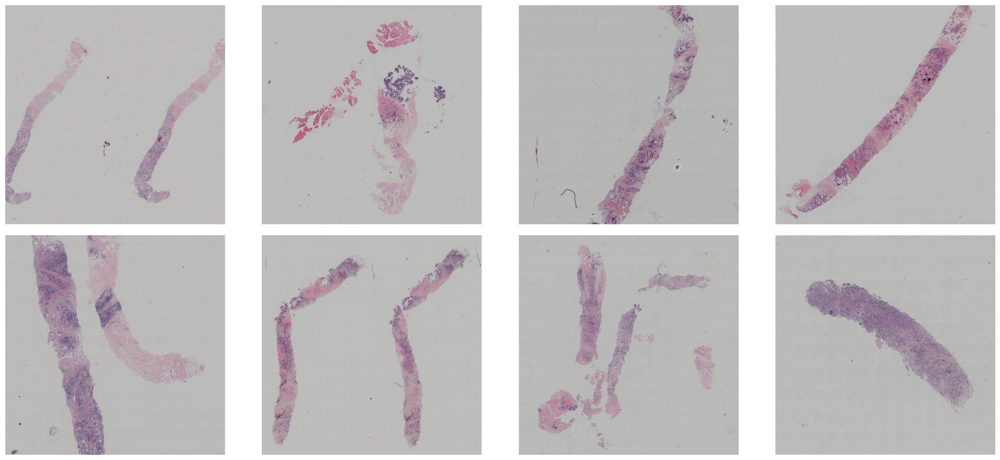

In [ ]:
# Number of images to display
num_img = 8
# Create subplots for displaying images
fig, axes = plt.subplots(2, num_img//2, figsize=(20, 9))
for i in range(num_img):
    ax = axes[i%2, i%num_img//2]

    # Load the image from its filepath
    img = cv2.imread(image_filepaths[i])

    # Check if image was loaded successfully
    if img is None:
        print(f"Warning: Could not load image from {image_filepaths[i]}")
        ax.set_title("Error loading image")
        ax.axis('off')
        continue

    # Normalize image pixel values to a float range [0, 1]
    img = (img / 255).astype(np.float32)

    # Convert image from BGR to RGB for matplotlib
    img = img[...,::-1]

    # Make the image dataset squared
    dim = min(img.shape[:-1])
    img = img[(img.shape[0]-dim)//2:(img.shape[0]+dim)//2,
              (img.shape[1]-dim)//2:(img.shape[1]+dim)//2, :]

    # Resize the image to IMG_SIZE x IMG_SIZE pixels
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    ax.imshow(np.clip(img, 0, 1))
    ax.axis('off')
plt.tight_layout()
plt.show()

Displaying images and their corresponding masks after numerical sorting:
  Image: img_0147.png, Mask: mask_0147.png
  Image: img_0035.png, Mask: mask_0035.png
  Image: img_0341.png, Mask: mask_0341.png
  Image: img_0306.png, Mask: mask_0306.png
  Image: img_0282.png, Mask: mask_0282.png


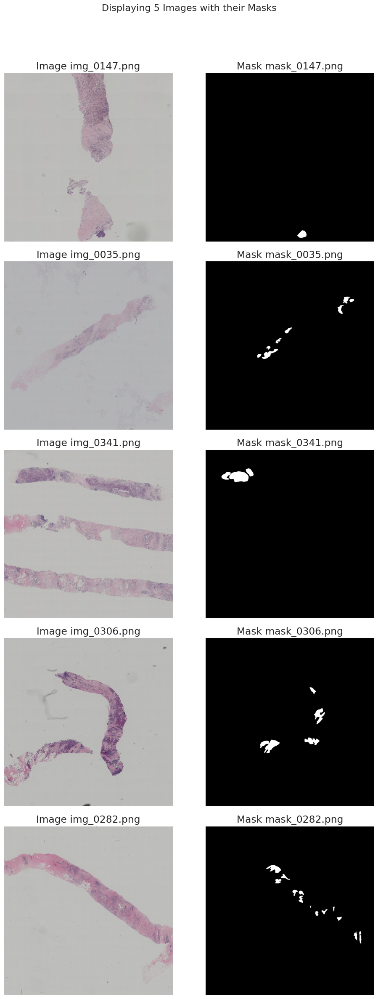

In [ ]:
def show_images_with_masks(image_filepaths, masks_filepaths, num_img=5):
    """
    Displays a given number of images and their corresponding masks side-by-side.

    Args:
        image_filepaths (list): List of image file paths.
        masks_filepaths (list): List of mask file paths, corresponding to image_filepaths.
        num_img (int): The number of image-mask pairs to display.
    """
    fig, axes = plt.subplots(num_img, 2, figsize=(10, 5 * num_img))
    fig.suptitle(f"Displaying {num_img} Images with their Masks", fontsize=16)

    if num_img == 1: # Handle single row case
        axes = [axes]

    for i in range(num_img):
        if i >= len(image_filepaths):
            break

        # Load the image
        img = cv2.imread(image_filepaths[i])
        mask = cv2.imread(masks_filepaths[i], cv2.IMREAD_GRAYSCALE)

        if img is None:
            print(f"Warning: Could not load image from {image_filepaths[i]}")
            continue
        if mask is None:
            print(f"Warning: Could not load mask from {masks_filepaths[i]}")
            continue

        # Convert image from BGR to RGB for matplotlib
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Make image and mask dataset squared
        dim = min(img.shape[:-1])
        y0 = (img.shape[0] - dim) // 2
        x0 = (img.shape[1] - dim) // 2

        img_cropped = img[y0:y0+dim, x0:x0+dim]
        mask_cropped = mask[y0:y0+dim, x0:x0+dim]

        # Resize to IMG_SIZE x IMG_SIZE
        img_resized = cv2.resize(img_cropped, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        mask_resized = cv2.resize(mask_cropped, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

        # Normalize image for display
        img_display = img_resized / 255.0

        # Display the image
        axes[i, 0].imshow(np.clip(img_display, 0, 1))
        axes[i, 0].set_title(f"Image {os.path.basename(image_filepaths[i])}")
        axes[i, 0].axis('off')

        # Display the mask
        axes[i, 1].imshow(mask_resized, cmap='gray')
        axes[i, 1].set_title(f"Mask {os.path.basename(masks_filepaths[i])}")
        axes[i, 1].axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Show 5 random images and their masks from the *already sorted* lists
random_indices = random.sample(range(len(image_filepaths)), min(5, len(image_filepaths)))
selected_image_filepaths = [image_filepaths[idx] for idx in random_indices]
selected_masks_filepaths = [masks_filepaths[idx] for idx in random_indices]

print("Displaying images and their corresponding masks after numerical sorting:")
for i in range(len(selected_image_filepaths)):
    print(f"  Image: {os.path.basename(selected_image_filepaths[i])}, Mask: {os.path.basename(selected_masks_filepaths[i])}")

show_images_with_masks(selected_image_filepaths, selected_masks_filepaths, num_img=5)

## **DATA PREPROCESSING**

**Data Exploration**

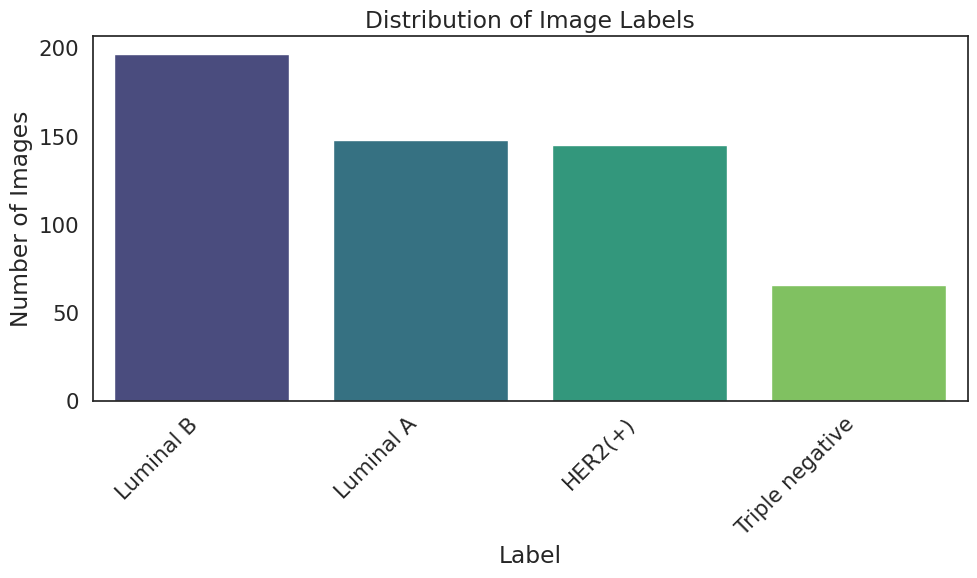

Label distribution:
Luminal B          197
Luminal A          148
HER2(+)            145
Triple negative     66
Name: count, dtype: int64


In [ ]:
# Get the counts of each label
label_counts = pd.Series(numerical_labels).value_counts().sort_index()

# Map numerical labels to their original names for better readability in the plot
label_names = {v: k for k, v in label_mapping.items()}
mapped_counts = label_counts.rename(index=label_names)

# Create a bar plot (histogram)
plt.figure(figsize=(10, 6))
sns.barplot(x=mapped_counts.index, y=mapped_counts.values, palette='viridis')
plt.title('Distribution of Image Labels')
plt.xlabel('Label')
plt.ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Label distribution:")
print(mapped_counts)


**DATA CLEANING**

In [ ]:
def detect_green_spots(image_rgb):
    """
    Detects the presence of green spots in an RGB image using HSV color space and masking.

    Args:
        image_rgb (np.ndarray): The input image in RGB format (NumPy array).

    Returns:
        bool: True if green spots are detected, False otherwise.
    """
    # Convert the image from RGB to HSV color space
    image_hsv = cv2.cvtColor((image_rgb * 255).astype(np.uint8), cv2.COLOR_RGB2HSV)

    # Define the lower and upper bounds for green color in HSV
    # For typical green, H (hue) ranges from ~30-90, S (saturation) and V (value) from ~50-255
    lower_green = np.array([30, 50, 50])
    upper_green = np.array([90, 255, 255])

    # Create a mask that isolates pixels within the defined green HSV range
    mask = cv2.inRange(image_hsv, lower_green, upper_green)

    # Check if any pixels in the created mask are white (indicating the presence of green pixels)
    # If the sum of all pixel values in the mask is greater than 0, it means there are white pixels
    if np.any(mask):
        return True
    else:
        return False


In [ ]:
cleaned_filepaths = []
cleaned_numerical_labels = []
cleaned_masks = []
removed_count = 0

# Iterate through the initially loaded filepaths and numerical labels
for i, filepath in enumerate(image_filepaths):
    # Load the image from its filepath
    img_bgr = cv2.imread(filepath)

    # Check if image was loaded successfully
    if img_bgr is None:
        print(f"Warning: Could not load image from {filepath} for cleaning. Skipping.")
        removed_count += 1 # Count as removed if it couldn't be loaded
        continue

    # Convert image from BGR to RGB
    img_rgb = img_bgr[...,::-1]

    # Make the image dataset squared (preprocessing for consistent detection)
    # Use IMG_SIZE from the global scope (cell bX9u21LH7VRy)
    dim = min(img_rgb.shape[:-1])
    img_squared = img_rgb[(img_rgb.shape[0]-dim)//2:(img_rgb.shape[0]+dim)//2,
                          (img_rgb.shape[1]-dim)//2:(img_rgb.shape[1]+dim)//2, :]

    # Resize the image to IMG_SIZE x IMG_SIZE pixels for consistent detection
    # detect_green_spots expects RGB float [0,1]
    img_resized = cv2.resize(img_squared, (IMG_SIZE, IMG_SIZE))
    img_float_for_detection = (img_resized / 255.0).astype(np.float32)


    # Check for green spots
    if not detect_green_spots(img_float_for_detection):
        cleaned_filepaths.append(filepath)
        cleaned_masks.append(masks_filepaths[i])
        cleaned_numerical_labels.append(numerical_labels[i])
    else:
        removed_count += 1

# Update the global image_filepaths and numerical_labels lists
image_filepaths = cleaned_filepaths
numerical_labels = cleaned_numerical_labels
masks_filepaths = cleaned_masks

print(f"Number of images removed due to green spots: {removed_count}")
print(f"New number of image filepaths: {len(image_filepaths)}")
print(f"New number of numerical labels: {len(numerical_labels)}")
print(f"New number of mask filepaths: {len(masks_filepaths)}")

Number of images removed due to green spots: 2
New number of image filepaths: 554
New number of numerical labels: 554
New number of mask filepaths: 554


**Showing some images for different labels**

In [ ]:
def show_n_images_for_label(filepaths_list, labels_list, label_name, n=5):
    """
    Displays the first n images of a specific label.

    Args:
        filepaths_list (list): List of image file paths.
        labels_list (list): List of numerical labels corresponding to the file paths.
        label_name (str): The name of the label to display (e.g., 'Luminal B').
        n (int): The number of images to display for the given label.
    """
    # Map the label name back to its numerical representation
    try:
        numerical_label = label_mapping[label_name]
    except KeyError:
        print(f"Error: Label '{label_name}' not found in label_mapping.")
        return

    # Filter file paths for the specified numerical_label
    filtered_filepaths = []
    for i, label in enumerate(labels_list):
        if label == numerical_label:
            filtered_filepaths.append(filepaths_list[i])

    if not filtered_filepaths:
        print(f"No images found for label: {label_name}")
        return

    # Determine how many images to show (min of n or available images)
    num_to_show = min(n, len(filtered_filepaths))

    # Create subplots
    fig, axes = plt.subplots(1, num_to_show, figsize=(4 * num_to_show, 4))
    fig.suptitle(f"First {num_to_show} images for label: {label_name}", fontsize=16)

    # Handle case with single image
    if num_to_show == 1:
        axes = [axes]

    for i in range(num_to_show):
        ax = axes[i]
        filepath = filtered_filepaths[i]

        # Load the image from its filepath
        img = cv2.imread(filepath)

        # Check if image was loaded successfully
        if img is None:
            print(f"Warning: Could not load image from {filepath}")
            ax.set_title("Error loading image")
            ax.axis('off')
            continue

        # Normalize image pixel values to a float range [0, 1]
        img = (img / 255).astype(np.float32)

        # Convert image from BGR to RGB for matplotlib
        img = img[...,::-1]

        # Make the image dataset squared
        dim = min(img.shape[:-1])
        img = img[(img.shape[0]-dim)//2:(img.shape[0]+dim)//2,
                  (img.shape[1]-dim)//2:(img.shape[1]+dim)//2, :]

        # Resize the image to IMG_SIZE x IMG_SIZE pixels
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(f"Label: {label_name}")
        ax.axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
    plt.show()

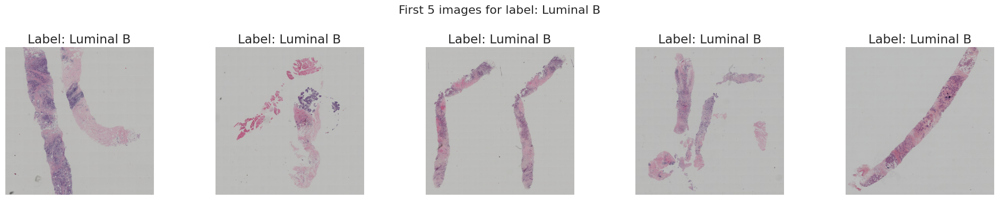

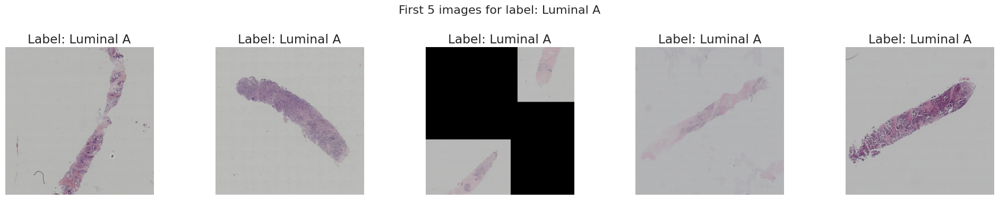

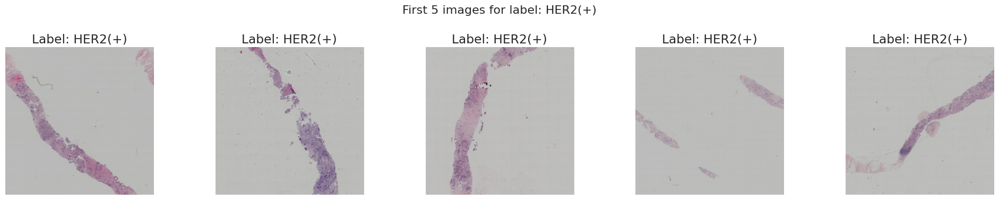

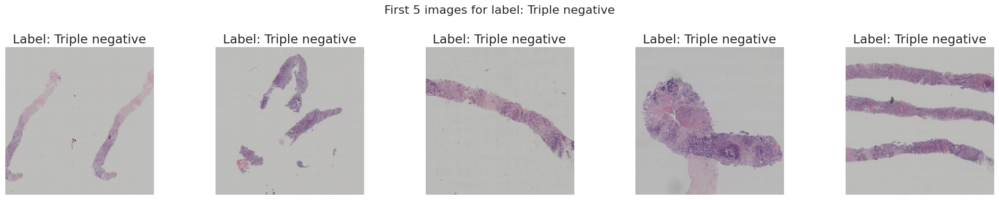

In [ ]:
show_n_images_for_label(image_filepaths, numerical_labels, 'Luminal B', 5)
show_n_images_for_label(image_filepaths, numerical_labels, 'Luminal A', 5)
show_n_images_for_label(image_filepaths, numerical_labels, 'HER2(+)', 5)
show_n_images_for_label(image_filepaths, numerical_labels, 'Triple negative', 5)

**VALIDATION AND TEST SPLITTING**

In [ ]:
# Split data into training and validation sets
X_train_filepaths, X_val_filepaths, y_train, y_val, X_train_masks, X_val_masks = train_test_split(
    image_filepaths, numerical_labels, masks_filepaths, test_size=0.2, random_state=SEED, stratify=numerical_labels
)
input_shape = (4, IMG_SIZE, IMG_SIZE)

print(f"Training image filepaths length: {len(X_train_filepaths)}")
print(f"Validation image filepaths length: {len(X_val_filepaths)}")
print(f"Training labels length: {len(y_train)}")
print(f"Validation labels length: {len(y_val)}")
print(f"Training mask filepaths length: {len(X_train_masks)}")
print(f"Validation mask filepaths length: {len(X_val_masks)}")
print(f"Initial model input shape (based on original IMG_SIZE): {input_shape}")

Training image filepaths length: 443
Validation image filepaths length: 111
Training labels length: 443
Validation labels length: 111
Training mask filepaths length: 443
Validation mask filepaths length: 111
Initial model input shape (based on original IMG_SIZE): (4, 1024, 1024)


Function for filtering blank patches

In [ ]:
import cv2
import numpy as np

def tissue_mask(img_rgb, sat_thresh=20):
    """
    Generates a binary mask identifying tissue regions in an RGB image based on saturation.

    Args:
        img_rgb (np.ndarray): The input image in RGB format (NumPy array, uint8 type).
        sat_thresh (int): Saturation threshold to distinguish tissue from background.

    Returns:
        np.ndarray: A binary mask (uint8) where 255 indicates tissue and 0 indicates background.
    """
    # Convert to HSV. Input `img_rgb` is expected to be RGB (uint8).
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV) # Corrected COLOR_BGR2HSV to COLOR_RGB2HSV
    h, s, v = cv2.split(hsv)

    # Tissue often has higher saturation than background
    mask = s > sat_thresh

    # Convert boolean mask to uint8 (0 or 255)
    mask = mask.astype(np.uint8) * 255

    return mask

## **Image Augmentation & Patch Cropping**

**Creating Pacth Dataset Class**

In [ ]:
class PatchDataset(torch.utils.data.Dataset):
    def __init__(self, images_filepaths, masks_filepaths, labels,
                 transform=None, patch_size=224, stride=224,
                 min_tissue_ratio=0.1):

        self.transform = transform
        self.patch_size = patch_size
        self.stride = stride
        self.min_tissue_ratio = min_tissue_ratio

        self.images = []      # list of processed RGB images (uint8)
        self.masks = []       # list of processed mask images (uint8, 0/255)
        self.labels = []      # Filtered labels for successfully processed images
        self.patches_info = []  # (image_idx, x, y)

        processed_image_count = 0 # To track index for self.images, self.masks, self.labels

        # ------------------------------
        # PREPROCESS ALL IMAGES & MASKS
        # ------------------------------
        for idx, (img_path, mask_path) in enumerate(zip(images_filepaths, masks_filepaths)):

            # ------------------------
            # Load RGB image
            # ------------------------
            img_bgr = cv2.imread(img_path)
            if img_bgr is None:
                print(f"[WARN] Could not load image {img_path}. Skipping.")
                continue
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) # Correctly get RGB once

            # ------------------------
            # Load mask image
            # ------------------------
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is None:
                print(f"[WARN] Could not load mask {mask_path}. Skipping.")
                continue

            # Get dimensions from the image
            h_img, w_img, _ = img_rgb.shape
            if h_img == 0 or w_img == 0:
                print(f"[WARN] Image {img_path} has zero dimensions after loading. Skipping.")
                continue

            # Ensure mask has the same dimensions as the image
            h_mask, w_mask = mask.shape
            if h_mask != h_img or w_mask != w_img:
                print(f"[INFO] Resizing mask {mask_path} from {h_mask}x{w_mask} to match image {h_img}x{w_img}.")
                mask = cv2.resize(mask, (w_img, h_img), interpolation=cv2.INTER_NEAREST)

            # Now crop both image and mask consistently
            dim = min(h_img, w_img)
            y0 = (h_img - dim) // 2
            x0 = (w_img - dim) // 2

            img_cropped = img_rgb[y0:y0+dim, x0:x0+dim]
            mask_cropped = mask[y0:y0+dim, x0:x0+dim]

            # Resize both cropped image and mask to IMG_SIZE x IMG_SIZE
            img_resized_uint8 = cv2.resize(img_cropped, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA).astype(np.uint8)
            mask_resized_uint8 = cv2.resize(mask_cropped, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

            # Convert to binary 0/255
            mask_resized_uint8 = (mask_resized_uint8 > 0).astype(np.uint8) * 255

            # ------------------------
            # Compute tissue mask ON THE RGB IMAGE (already resized to IMG_SIZE)
            # ------------------------
            tissue = tissue_mask(img_resized_uint8)

            # ------------------------
            # Generate patches for this image
            # ------------------------
            H, W = IMG_SIZE, IMG_SIZE
            patches_generated_for_current_image = 0
            for y in range(0, H - patch_size + 1, stride):
                for x in range(0, W - patch_size + 1, stride):

                    region = tissue[y:y+patch_size, x:x+patch_size]
                    if np.mean(region > 0) >= min_tissue_ratio:
                        self.patches_info.append((processed_image_count, x, y))
                        patches_generated_for_current_image += 1

            # Only store image, mask, and label if at least one patch was generated from them
            if patches_generated_for_current_image > 0:
                self.images.append(img_resized_uint8)
                self.masks.append(mask_resized_uint8)
                self.labels.append(labels[idx]) # Associate original label with successfully processed image
                processed_image_count += 1
            else:
                print(f"[INFO] No valid patches found for {img_path} based on min_tissue_ratio. Skipping image.")

        print(f"Prepared {len(self.images)} images and {len(self.patches_info)} valid patches.")

    # ------------------------
    def __len__(self):
        return len(self.patches_info)

    # ------------------------
    def __getitem__(self, idx):
        image_idx, x, y = self.patches_info[idx]
        label = self.labels[image_idx]

        # Extract RGB patch
        img = self.images[image_idx]
        patch_rgb = img[y:y+self.patch_size, x:x+self.patch_size]

        # Extract mask patch
        mask = self.masks[image_idx]
        patch_mask = mask[y:y+self.patch_size, x:x+self.patch_size]

        # Convert to PIL
        patch_rgb = Image.fromarray(patch_rgb)
        patch_mask = Image.fromarray(patch_mask)

        # Apply base transforms (resize/type conversion for both)
        # Using torchvision.transforms.ToTensor() directly
        patch_rgb = transforms.ToTensor()(patch_rgb)
        patch_mask = transforms.ToTensor()(patch_mask)

        # Binary 0/1 mask
        patch_mask = (patch_mask > 0.5).float()

        # Merge channels → (4, H, W)
        patch = torch.cat([patch_rgb, patch_mask], dim=0)

        # Apply augmentation on the 4-channel patch only if transform provided
        if self.transform:
            patch = self.transform(patch)

        return patch, torch.tensor(label, dtype=torch.long)

Metrics for Patch Training

In [ ]:
PATCH_SIZE = 256
STRIDE = 256

MIN_TISSUE_RATIO = 0.4

print(f"Patch Size: {PATCH_SIZE}x{PATCH_SIZE}")
print(f"Stride: {STRIDE}")

Patch Size: 256x256
Stride: 256


Augmentation for 4 channels

In [ ]:
import torch
import torchvision.transforms.functional as TF
import random

class FourChannelAugment:
    def __init__(self,
                 brightness=0.2,
                 contrast=0.2,
                 saturation=0.2,
                 hue=0.02,
                 rotation=180,
                 hflip=True,
                 vflip=True):

        self.color_jitter = transforms.ColorJitter(
            brightness=brightness,
            contrast=contrast,
            saturation=saturation,
            hue=hue
        )

        self.rotation = rotation
        self.hflip = hflip
        self.vflip = vflip

    def __call__(self, x):
        """
        x: Tensor with shape (4, H, W)
        """
        assert x.shape[0] == 4, "Expected 4-channel input (RGB + MASK)"

        rgb = x[:3, :, :]
        mask = x[3:, :, :]  # shape: (1, H, W)

        # ---- Geometric augmentations applied to BOTH ----
        if self.hflip and random.random() < 0.5:
            rgb = torch.flip(rgb, dims=[2])
            mask = torch.flip(mask, dims=[2])

        if self.vflip and random.random() < 0.5:
            rgb = torch.flip(rgb, dims=[1])
            mask = torch.flip(mask, dims=[1])

        if self.rotation:
            angle = random.uniform(-self.rotation, self.rotation)
            rgb = TF.rotate(rgb, angle)
            # nearest interpolation prevents mask grayscaling
            mask = TF.rotate(mask, angle, interpolation=transforms.InterpolationMode.NEAREST)

        # ---- Color jitter on RGB ONLY ----
        # Convert to PIL for jitter
        rgb_pil = TF.to_pil_image(rgb)
        rgb_pil = self.color_jitter(rgb_pil)
        rgb = TF.to_tensor(rgb_pil)

        # Ensure mask stays binary
        mask = (mask > 0.5).float()

        # Recombine into 4 channels
        x_aug = torch.cat([rgb, mask], dim=0)
        return x_aug

In [ ]:
# Define image transformations for training and validation for 4 channels

# Note: PatchDataset already returns a 4-channel Tensor (RGB + Mask)
# with the patch_size applied. So, we only need augmentations and normalization.

train_transform = transforms.Compose([
    FourChannelAugment(
        brightness=0.25,
        contrast=0.25,
        saturation=0.25,
        hue=0.03,
        rotation=180,
        hflip=True,
        vflip=True
    ),
    # Normalize 4 channels: RGB (0.485, 0.456, 0.406), Mask (0.0)
    # Std: RGB (0.229, 0.224, 0.225), Mask (1.0) - keeps mask binary 0/1
    transforms.Normalize(mean=[0.485, 0.456, 0.406, 0.0],
                         std=[0.229, 0.224, 0.225, 1.0])
])


val_transform = transforms.Compose([
    # For validation, no geometric augmentation is typically applied
    # Normalize 4 channels: RGB (0.485, 0.456, 0.406), Mask (0.0)
    # Std: RGB (0.229, 0.224, 0.225), Mask (1.0) - keeps mask binary 0/1
    transforms.Normalize(mean=[0.485, 0.456, 0.406, 0.0],
                         std=[0.229, 0.224, 0.225, 1.0])
])

In [ ]:
# Create datasets with transformations using PatchDataset
train_dataset_patched = PatchDataset(X_train_filepaths, X_train_masks, y_train, transform=train_transform, patch_size=PATCH_SIZE, stride=STRIDE, min_tissue_ratio=MIN_TISSUE_RATIO)
val_dataset_patched = PatchDataset(X_val_filepaths, X_val_masks, y_val, transform=val_transform, patch_size=PATCH_SIZE, stride=STRIDE, min_tissue_ratio=MIN_TISSUE_RATIO)


# Update the input_shape to reflect the new patch size (IMG_SIZE after transformations)
# Note: input_shape here should reflect the final size of the patch fed to the model
# If patches are PATCH_SIZE x PATCH_SIZE, then input_shape should be (channels, PATCH_SIZE, PATCH_SIZE)
input_shape = (4, PATCH_SIZE, PATCH_SIZE)
print(f"Updated model input shape: {input_shape}")

[INFO] No valid patches found for train_data_updated/img_0365.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0223.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0277.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0458.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0352.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0478.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0375.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0300.png based on min_tissue_ratio. Skipping image.
[INFO] No valid patches found for train_data_updated/img_0334.png based on min_tissue_ratio. Skipping image.
[INFO] No valid pat

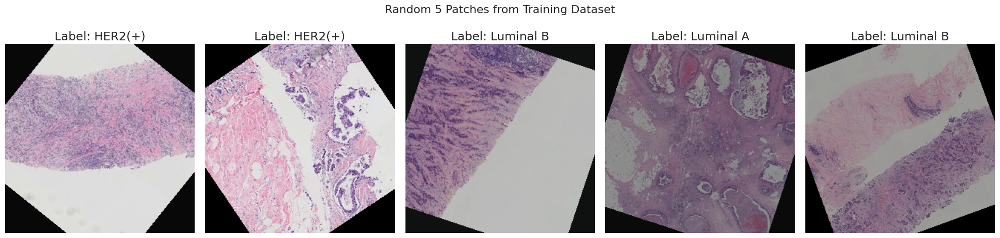

In [ ]:
num_patches_to_show = 5

fig, axes = plt.subplots(1, num_patches_to_show, figsize=(20, 5))
fig.suptitle(f"Random {num_patches_to_show} Patches from Training Dataset", fontsize=16)

# Map numerical labels to their original names for display
label_names_display = {v: k for k, v in label_mapping.items()}

for i in range(num_patches_to_show):
    # Get a random index from the patched dataset
    random_idx = random.randint(0, len(train_dataset_patched) - 1)

    # Get the patch and label using __getitem__
    patch_tensor, numerical_label = train_dataset_patched[random_idx]

    # Convert the tensor to a NumPy array for display
    # Permute dimensions from C, H, W to H, W, C
    patch_np = patch_tensor.permute(1, 2, 0).cpu().numpy()

    # Un-normalize for display purposes
    # Define mean and std for RGB channels
    mean_rgb = np.array([0.485, 0.456, 0.406])
    std_rgb = np.array([0.229, 0.224, 0.225])

    # Apply un-normalization only to the RGB channels (first 3 channels)
    display_rgb = std_rgb * patch_np[:, :, :3] + mean_rgb

    ax = axes[i]
    ax.imshow(np.clip(display_rgb, 0, 1)) # Clip values to [0, 1] to avoid display issues
    ax.set_title(f"Label: {label_names_display[numerical_label.item()]}")
    ax.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

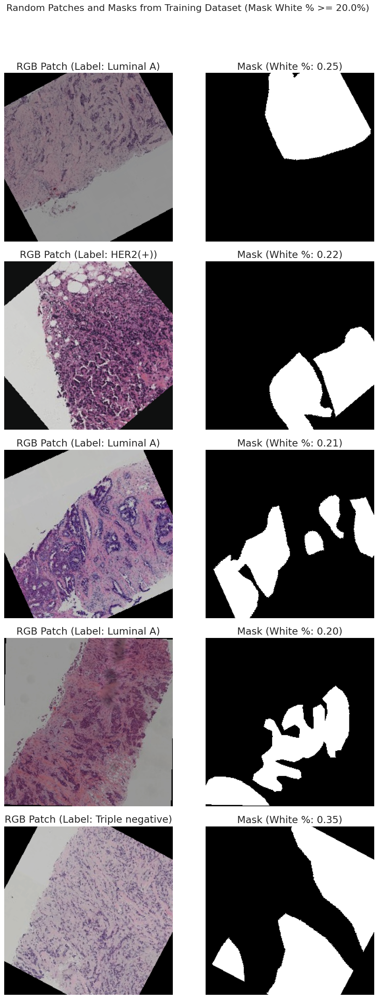

In [ ]:
num_patches_to_show = 5
min_mask_white_percentage = 0.2
max_retries = 100 # Safeguard against infinite loops if no suitable patches are found

fig, axes = plt.subplots(num_patches_to_show, 2, figsize=(10, 5 * num_patches_to_show))
fig.suptitle(f"Random Patches and Masks from Training Dataset (Mask White % >= {min_mask_white_percentage*100}%) ", fontsize=16)

# Map numerical labels to their original names for display
label_names_display = {v: k for k, v in label_mapping.items()}

# Define mean and std for RGB channels
mean_rgb = np.array([0.485, 0.456, 0.406])
std_rgb = np.array([0.229, 0.224, 0.225])

for i in range(num_patches_to_show):
    found_suitable_patch = False
    retries = 0
    while not found_suitable_patch and retries < max_retries:
        # Get a random index from the patched dataset
        random_idx = random.randint(0, len(train_dataset_patched) - 1)

        # Get the patch and label using __getitem__
        patch_tensor, numerical_label = train_dataset_patched[random_idx]

        # Convert the tensor to a NumPy array for display
        # Permute dimensions from C, H, W to H, W, C
        patch_np = patch_tensor.permute(1, 2, 0).cpu().numpy()

        # Separate RGB and Mask
        rgb_patch = patch_np[:, :, :3]
        mask_patch = patch_np[:, :, 3] # This is already 0 or 1 float

        # Check if the mask has a certain white percentage
        if np.mean(mask_patch) >= min_mask_white_percentage:
            found_suitable_patch = True
        else:
            retries += 1

    if not found_suitable_patch:
        print(f"Warning: Could not find a patch with at least {min_mask_white_percentage*100}% white in mask after {max_retries} retries. Skipping this display slot.")
        axes[i, 0].set_title("No suitable patch found")
        axes[i, 0].axis('off')
        axes[i, 1].axis('off')
        continue

    # Un-normalize RGB channels for display
    display_rgb = std_rgb * rgb_patch + mean_rgb

    # Display RGB patch
    ax_rgb = axes[i, 0]
    ax_rgb.imshow(np.clip(display_rgb, 0, 1)) # Clip values to [0, 1]
    ax_rgb.set_title(f"RGB Patch (Label: {label_names_display[numerical_label.item()]})")
    ax_rgb.axis('off')

    # Display Mask patch
    ax_mask = axes[i, 1]
    ax_mask.imshow(mask_patch, cmap='gray') # Masks are grayscale
    ax_mask.set_title(f"Mask (White %: {np.mean(mask_patch):.2f})")
    ax_mask.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
plt.show()

## 🚧 **BUILDING THE MODEL**

**CREATE DATALOADER**


In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last):
    """
    Create a PyTorch DataLoader with optimized settings.

    Args:
        ds (Dataset): PyTorch Dataset object
        batch_size (int): Number of samples per batch
        shuffle (bool): Whether to shuffle data at each epoch
        drop_last (bool): Whether to drop last incomplete batch

    Returns:
        DataLoader: Configured DataLoader instance
    """
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

batch_size = 32

train_loader = make_loader(train_dataset_patched, batch_size, shuffle=True, drop_last=True)
val_loader = make_loader(val_dataset_patched,batch_size=batch_size,shuffle=True,drop_last=True)



In [ ]:
class CustomTransferLearningModel(nn.Module):
    """
    General transfer learning module supporting various torchvision models.
    """

    def __init__(self, num_classes, model_name="resnet18",
                 dropout_rate=0.3, freeze_backbone=True):

        super().__init__()

        # Load backbone and weights
        if model_name.startswith("resnet"):
            if model_name == "resnet18":
                weights = torchvision.models.ResNet18_Weights.DEFAULT
            elif model_name == "resnet34":
                weights = torchvision.models.ResNet34_Weights.DEFAULT
            else:
                raise ValueError(f"Unsupported ResNet model_name: {model_name}")
            self.backbone = getattr(torchvision.models, model_name)(weights=weights)
            in_features = self.backbone.fc.in_features
            # Replace classifier head
            self.backbone.fc = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
        elif model_name.startswith("convnext"):
            if model_name == "convnext_tiny":
                weights = torchvision.models.ConvNeXt_Tiny_Weights.DEFAULT
            elif model_name == "convnext_small":
                weights = torchvision.models.ConvNeXt_Small_Weights.DEFAULT
            elif model_name == "convnext_base":
                weights = torchvision.models.ConvNeXt_Base_Weights.DEFAULT
            elif model_name == "convnext_large":
                weights = torchvision.models.ConvNeXt_Large_Weights.DEFAULT
            else:
                raise ValueError(f"Unsupported ConvNeXt model_name: {model_name}")
            self.backbone = getattr(torchvision.models, model_name)(weights=weights)
            in_features = self.backbone.classifier[2].in_features
            # Replace classifier head
            self.backbone.classifier[2] = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
        else:
            raise ValueError(f"Unsupported model_name: {model_name}")

        # Freeze backbone parameters
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
            # Ensure the new classifier head parameters are trainable
            if model_name.startswith("resnet"):
                for param in self.backbone.fc.parameters():
                    param.requires_grad = True
            elif model_name.startswith("convnext"):
                for param in self.backbone.classifier[2].parameters():
                    param.requires_grad = True

    def forward(self, x):
        return self.backbone(x)


**TRAIN ONE EPOCH**

In [ ]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm

        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

**VALIDATE ONE EPOCH**

In [ ]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [ ]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

**FIT**

In [ ]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [ ]:
class WeightedFocalLoss(nn.Module):
    """
    Weighted Focal Loss for classification tasks.

    Args:
        alpha (list or torch.Tensor): A list or tensor of weights for each class.
                                       If None, all classes are weighted equally.
        gamma (float): Focusing parameter for Focal Loss. A higher gamma reduces the loss
                       contribution from easy examples and increases the importance of
                       misclassified examples.
        reduction (str): Specifies the reduction to apply to the output: 'none' | 'mean' | 'sum'.
                         'none': no reduction will be applied,
                         'mean': the sum of the output will be divided by the number of elements in the output,
                         'sum': the output will be summed.
    """
    def __init__(self, alpha=None, gamma=2, reduction='mean'):
        super().__init__()
        if alpha is not None:
            # Convert alpha to a tensor if it's a list
            if isinstance(alpha, list):
                alpha = torch.tensor(alpha, dtype=torch.float32)
            self.alpha = alpha
        else:
            self.alpha = None # No class weights

        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        # Ensure inputs are in float32 for log_softmax
        inputs = inputs.float()

        # Get probabilities using log_softmax and then exp
        log_prob = F.log_softmax(inputs, dim=1)
        prob = torch.exp(log_prob)

        # Select the probabilities corresponding to the true target classes
        # This effectively creates a 1-hot encoded vector and multiplies by prob
        pt = prob.gather(1, targets.long().view(-1, 1)).squeeze()

        # Compute (1 - pt)^gamma, the focal term
        focal_term = (1 - pt)**self.gamma

        # Calculate cross-entropy part of the loss
        cross_entropy_loss = -log_prob.gather(1, targets.long().view(-1, 1)).squeeze()

        # Apply alpha (class weights) if provided
        if self.alpha is not None:
            # Move alpha to the same device as inputs
            self.alpha = self.alpha.to(inputs.device)
            class_weights = self.alpha.gather(0, targets.long().view(-1))
            loss = class_weights * focal_term * cross_entropy_loss
        else:
            loss = focal_term * cross_entropy_loss

        # Apply reduction
        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        else:
            return loss



In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet34

def convert_resnet_to_4ch(model):
    # Existing conv1: (64, 3, 7, 7)
    old_conv = model.conv1

    new_conv = nn.Conv2d(
        in_channels=4,
        out_channels=64,
        kernel_size=7,
        stride=2,
        padding=3,
        bias=(old_conv.bias is not None)
    )

    # Copy pretrained RGB weights
    new_conv.weight[:, :3, :, :] = old_conv.weight

    # Initialize 4th-channel weights to *zero* (recommended for masks)
    # → Let the model learn how to use the mask instead of forcing colors
    new_conv.weight[:, 3:4, :, :] = torch.zeros_like(old_conv.weight[:, 0:1, :, :])

    # Copy bias
    if old_conv.bias is not None:
        new_conv.bias = old_conv.bias

    model.conv1 = new_conv
    return model



## 🥊**MODEL TRAINING**

In [ ]:
import torch.nn.functional as F
#PARAMETERS
LEARNING_RATE = 1e-3 # For transfer learning, you might start with a lower learning rate, e.g., 1e-4 or 1e-5, especially if fine-tuning all layers.
                     # If only training the new head, a higher learning rate like 1e-3 might be acceptable.
EPOCHS = 400
PATIENCE = 50

# Regularisation
DROPOUT_RATE = 0.3         # Dropout probability
L1_LAMBDA = 0              # L1 penalty
L2_LAMBDA = 5e-4              # L2 penalty


# Calculating class wheights
label_counts_dict = mapped_counts.to_dict()
ordered_counts = [label_counts_dict[name] for name in label_names.values()]
total_samples = sum(ordered_counts)
num_classes = len(ordered_counts)

# Inverse frequency weighting:
class_weights = [total_samples / count for count in ordered_counts]
class_weights = torch.tensor(class_weights, dtype=torch.float32)
class_weights = class_weights / class_weights.sum() # Normalize weights

print(f"Calculated class weights: {class_weights.tolist()}")

# Set up loss function with weighted focal loss
criterion = WeightedFocalLoss(alpha=class_weights, gamma=2)


Calculated class weights: [0.14982283115386963, 0.1994263380765915, 0.20355239510536194, 0.44719845056533813]


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:01<00:00, 86.8MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 128, 128]          12,544
       BatchNorm2d-2         [-1, 64, 128, 128]             128
              ReLU-3         [-1, 64, 128, 128]               0
         MaxPool2d-4           [-1, 64, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          36,864
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
            Conv2d-8           [-1, 64, 64, 64]          36,864
       BatchNorm2d-9           [-1, 64, 64, 64]             128
             ReLU-10           [-1, 64, 64, 64]               0
       BasicBlock-11           [-1, 64, 64, 64]               0
           Conv2d-12           [-1, 64, 64, 64]          36,864
      BatchNorm2d-13           [-1, 64, 64, 64]             128
             ReLU-14           [-1, 64,

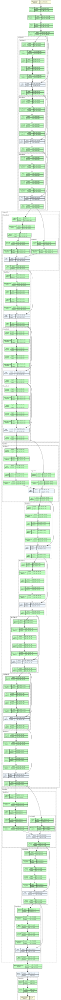

In [ ]:

import torch
import torch.nn as nn
from torchvision.models import resnet34

def convert_resnet_to_4ch(model):
    # Existing conv1: (64, 3, 7, 7)
    old_conv = model.conv1

    new_conv = nn.Conv2d(
        in_channels=4,
        out_channels=old_conv.out_channels, # Use old_conv.out_channels for generality
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=(old_conv.bias is not None)
    )

    # Copy pretrained RGB weights and initialize 4th channel to zero
    # Use .data to perform in-place operations without tracking gradients,
    # which is appropriate for weight initialization.
    new_conv.weight.data[:, :3, :, :] = old_conv.weight.data
    new_conv.weight.data[:, 3:4, :, :] = torch.zeros_like(old_conv.weight.data[:, 0:1, :, :])

    # Copy bias data directly if it exists
    if old_conv.bias is not None:
        new_conv.bias.data = old_conv.bias.data

    model.conv1 = new_conv
    return model

tl_model = resnet34(weights="IMAGENET1K_V1")
tl_model = convert_resnet_to_4ch(tl_model)
tl_model.fc = nn.Sequential(
    nn.Dropout(p=DROPOUT_RATE),
    nn.Linear(tl_model.fc.in_features, num_classes)
)

for param in tl_model.parameters():
    param.requires_grad = False
for param in tl_model.fc.parameters():
    param.requires_grad = True

tl_model.to(device) # Move the model to the specified device

# Display model summary
summary(tl_model, input_size=input_shape)
model_graph = draw_graph(tl_model, input_size=(batch_size,)+input_shape, expand_nested=True, depth=6)
model_graph.visual_graph

In [ ]:
# Set up TensorBoard logging and save model architecture
experiment_name = "Patch_training_4th_Channel"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1], input_shape[2]).to(device)
writer.add_graph(tl_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.Adam(tl_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

'\nfor imgs, labels in train_loader:   # imgs shape: [B,4,H,W]\n    optimizer.zero_grad()\n    preds = tl_model(imgs)\n    loss = criterion(preds, labels)\n    loss.backward()\n    optimizer.step()\n'

In [ ]:
%%time
# Train model and track training history
tl_model, vanilla_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=10,
    experiment_name=experiment_name,
    patience=PATIENCE
)

# Update best model if current performance is superior
if vanilla_history['val_f1'][-1] > best_performance:
    best_model = tl_model
    best_performance = vanilla_history['val_f1'][-1]

# Calculate and print the final validation F1 score
final_val_f1 = round(max(vanilla_history['val_f1']) * 100, 2)
print(f'Final validation F1 score: {final_val_f1}%')

Training 400 epochs...
Epoch   1/400 | Train: Loss=0.1983, F1 Score=0.2934 | Val: Loss=0.1672, F1 Score=0.1900
Epoch  10/400 | Train: Loss=0.1572, F1 Score=0.3357 | Val: Loss=0.1445, F1 Score=0.3010
Epoch  20/400 | Train: Loss=0.1533, F1 Score=0.3720 | Val: Loss=0.1485, F1 Score=0.2230
Epoch  30/400 | Train: Loss=0.1519, F1 Score=0.3581 | Val: Loss=0.1455, F1 Score=0.2383
Epoch  40/400 | Train: Loss=0.1401, F1 Score=0.4182 | Val: Loss=0.1568, F1 Score=0.2833
Epoch  50/400 | Train: Loss=0.1457, F1 Score=0.3673 | Val: Loss=0.1426, F1 Score=0.3375
Epoch  60/400 | Train: Loss=0.1435, F1 Score=0.3996 | Val: Loss=0.1554, F1 Score=0.3184
Epoch  70/400 | Train: Loss=0.1466, F1 Score=0.3758 | Val: Loss=0.1505, F1 Score=0.3082
Epoch  80/400 | Train: Loss=0.1479, F1 Score=0.3691 | Val: Loss=0.1454, F1 Score=0.2914
Epoch  90/400 | Train: Loss=0.1431, F1 Score=0.4045 | Val: Loss=0.1468, F1 Score=0.3743
Epoch 100/400 | Train: Loss=0.1536, F1 Score=0.3731 | Val: Loss=0.1566, F1 Score=0.2440
Epoch 110

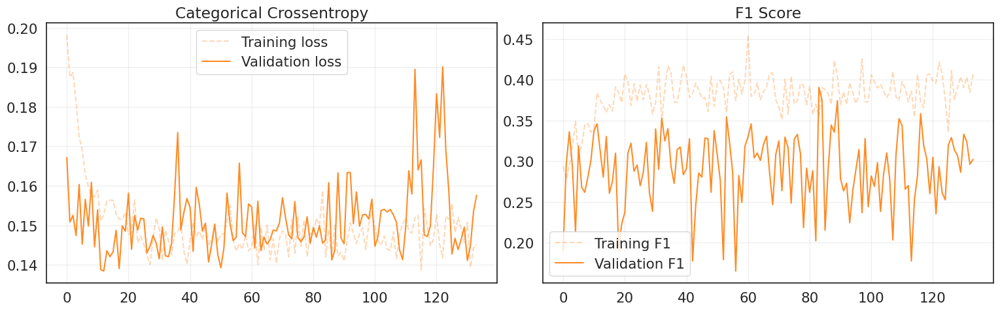

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(vanilla_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(vanilla_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation F1 score on the second axis
ax2.plot(vanilla_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(vanilla_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

**Plotting confusion matrix**

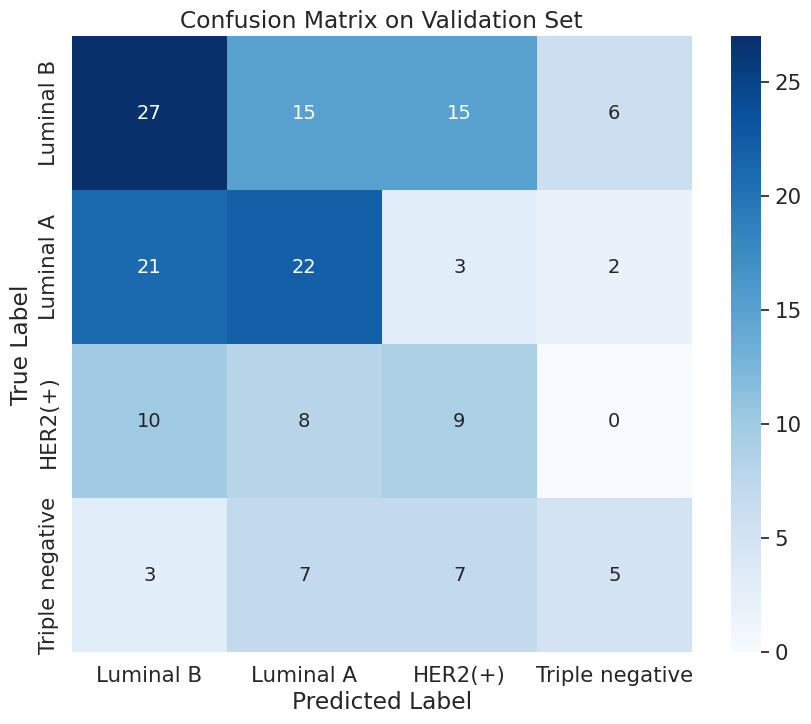

In [ ]:

# Ensure the model used here is the best_model obtained from training
# The best_model variable already holds the trained and loaded SimpleCNN_BN instance.
model = best_model # Use the best_model directly
model.eval() # Set to evaluation mode

def get_predictions(model, data_loader, device):
    all_predictions = []
    all_true_labels = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            all_predictions.extend(predicted.cpu().numpy())
            all_true_labels.extend(labels.cpu().numpy())
    return np.array(all_true_labels), np.array(all_predictions)

# Get predictions on the validation set
y_true_val, y_pred_val = get_predictions(model, val_loader, device)

# Generate confusion matrix
cm = confusion_matrix(y_true_val, y_pred_val)

# Map numerical labels back to their original names for display
label_names_ordered = [k for k, v in sorted(label_mapping.items(), key=lambda item: item[1])]

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names_ordered, yticklabels=label_names_ordered)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Validation Set')
plt.show()

## ☝**INFERENCE**

In [ ]:
#@title loading test Images
import os
import re

def load_images_Test_from_folder(folder):
    image_filepaths = []
    mask_filepaths = []
    filenames = [] # original filenames for submission

    # Collect all image and mask files in the folder
    all_files_in_folder = os.listdir(folder)

    # Dictionary to store mask paths by their corresponding image ID
    mask_lookup = {}
    for filename in all_files_in_folder:
        if filename.startswith("mask_") and filename.endswith(".png"):
            mask_id_match = re.search(r'mask_(\d+)\.png', filename)
            if mask_id_match:
                mask_lookup[int(mask_id_match.group(1))] = os.path.join(folder, filename)

    # Process image files and pair them with masks
    for filename in all_files_in_folder:
        if filename.startswith("img_") and filename.endswith(".png"):
            img_id_match = re.search(r'img_(\d+)\.png', filename)
            if img_id_match:
                img_id = int(img_id_match.group(1))
                corresponding_mask_path = mask_lookup.get(img_id)

                if corresponding_mask_path:
                    image_filepaths.append(os.path.join(folder, filename))
                    mask_filepaths.append(corresponding_mask_path)
                    filenames.append(filename)
                    print(f"Found filepath for {filename} and its mask.")
                else:
                    print(f"Warning: No corresponding mask found for {filename}. Skipping.")

    # Sort them by numerical ID to ensure consistent order
    # (img_id, img_path, mask_path, filename)
    combined_data = []
    for i in range(len(image_filepaths)):
        img_id = int(re.search(r'img_(\d+)\.png', os.path.basename(image_filepaths[i])).group(1))
        combined_data.append((img_id, image_filepaths[i], mask_filepaths[i], filenames[i]))

    combined_data.sort(key=lambda x: x[0])

    sorted_image_filepaths = [item[1] for item in combined_data]
    sorted_mask_filepaths = [item[2] for item in combined_data]
    sorted_filenames = [item[3] for item in combined_data]

    return sorted_image_filepaths, sorted_mask_filepaths, sorted_filenames

# Load image file paths
img_path = 'test_data_updated'
test_image_filepaths, test_masks_filepaths, names = load_images_Test_from_folder(img_path)
print(f"Loaded {len(test_image_filepaths)} image filepaths")
print(f"Loaded {len(test_masks_filepaths)} mask filepaths")
print(f"Loaded {len(names)} names")

Found filepath for img_0465.png and its mask.
Found filepath for img_0405.png and its mask.
Found filepath for img_0462.png and its mask.
Found filepath for img_0468.png and its mask.
Found filepath for img_0470.png and its mask.
Found filepath for img_0467.png and its mask.
Found filepath for img_0402.png and its mask.
Found filepath for img_0409.png and its mask.
Found filepath for img_0466.png and its mask.
Found filepath for img_0397.png and its mask.
Found filepath for img_0473.png and its mask.
Found filepath for img_0446.png and its mask.
Found filepath for img_0471.png and its mask.
Found filepath for img_0469.png and its mask.
Found filepath for img_0474.png and its mask.
Found filepath for img_0475.png and its mask.
Found filepath for img_0437.png and its mask.
Found filepath for img_0444.png and its mask.
Found filepath for img_0399.png and its mask.
Found filepath for img_0455.png and its mask.
Found filepath for img_0413.png and its mask.
Found filepath for img_0411.png an

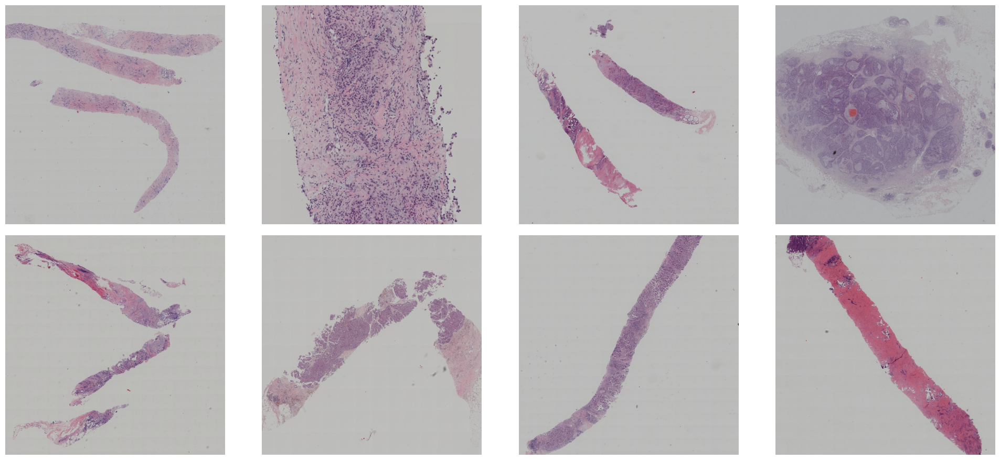

In [ ]:
# Number of images to display
num_img = 8
# Create subplots for displaying images
fig, axes = plt.subplots(2, num_img//2, figsize=(20, 9))
for i in range(num_img):
    ax = axes[i%2, i%num_img//2]

    # Load the image from its filepath
    img = cv2.imread(test_image_filepaths[i])

    # Check if image was loaded successfully
    if img is None:
        print(f"Warning: Could not load image from {test_image_filepaths[i]}")
        ax.set_title("Error loading image")
        ax.axis('off')
        continue

    # Normalize image pixel values to a float range [0, 1]
    img = (img / 255).astype(np.float32)

    # Convert image from BGR to RGB for matplotlib
    img = img[...,::-1]

    # Make the image dataset squared
    dim = min(img.shape[:-1])
    img = img[(img.shape[0]-dim)//2:(img.shape[0]+dim)//2,
              (img.shape[1]-dim)//2:(img.shape[1]+dim)//2, :]

    # Resize the image to IMG_SIZE x IMG_SIZE pixels
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    ax.imshow(np.clip(img, 0, 1))
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
class TestPatchDataset(torch.utils.data.Dataset):
    def __init__(self, image_filepath, mask_filepath, transform=None,
                 patch_size=256, stride=256,
                 target_size=None, min_tissue_ratio=0.1):

        self.transform = transform
        self.patch_size = patch_size
        self.stride = stride
        self.min_tissue_ratio = min_tissue_ratio
        self.patches_info = [] # (x, y) coordinates of patches

        # --- Load image ---
        img_bgr = cv2.imread(image_filepath)
        if img_bgr is None:
            raise FileNotFoundError(f"Failed to load image {image_filepath}")
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # --- Load mask ---
        mask_raw = cv2.imread(mask_filepath, cv2.IMREAD_GRAYSCALE)
        if mask_raw is None:
            raise FileNotFoundError(f"Failed to load mask {mask_filepath}")

        # --- Square crop and resize both image and mask consistently ---
        h_img, w_img = img_rgb.shape[:2]
        h_mask, w_mask = mask_raw.shape[:2]

        # Ensure mask and image have same initial dimensions (handle potential discrepancies during loading)
        if h_img != h_mask or w_img != w_mask:
            print(f"[WARN] Image and mask dimensions mismatch for {os.path.basename(image_filepath)}. Resizing mask.")
            mask_raw = cv2.resize(mask_raw, (w_img, h_img), interpolation=cv2.INTER_NEAREST)

        dim = min(h_img, w_img)
        crop_y = (h_img - dim) // 2
        crop_x = (w_img - dim) // 2

        img_sq = img_rgb[crop_y:crop_y + dim, crop_x:crop_x + dim]
        mask_sq = mask_raw[crop_y:crop_y + dim, crop_x:crop_x + dim]

        target = target_size if target_size is not None else IMG_SIZE
        self.img_resized_uint8 = cv2.resize(img_sq, (target, target), interpolation=cv2.INTER_AREA).astype(np.uint8)
        self.mask_resized_uint8 = cv2.resize(mask_sq, (target, target), interpolation=cv2.INTER_NEAREST).astype(np.uint8)

        # Convert mask to binary (0 or 255)
        self.mask_resized_uint8 = (self.mask_resized_uint8 > 0).astype(np.uint8) * 255

        # --- Compute tissue mask for patch selection ---
        tissue = tissue_mask(self.img_resized_uint8)

        H, W = tissue.shape

        # --- Precompute valid patches ---
        for sy in range(0, H - patch_size + 1, stride):
            for sx in range(0, W - patch_size + 1, stride):
                patch_region_tissue = tissue[sy : sy + patch_size,
                                            sx : sx + patch_size]

                if np.mean(patch_region_tissue > 0) >= min_tissue_ratio:
                    self.patches_info.append((sx, sy))

    def __len__(self):
        return len(self.patches_info)

    def __getitem__(self, idx):
        sx, sy = self.patches_info[idx]

        # Extract RGB patch
        patch_rgb = self.img_resized_uint8[
            sy : sy + self.patch_size,
            sx : sx + self.patch_size,
            :
        ]

        # Extract Mask patch
        patch_mask = self.mask_resized_uint8[
            sy : sy + self.patch_size,
            sx : sx + self.patch_size
        ]

        # Convert to PIL for transforms
        patch_rgb_pil = Image.fromarray(patch_rgb)
        patch_mask_pil = Image.fromarray(patch_mask)

        # Convert to Tensor first
        patch_rgb_tensor = transforms.ToTensor()(patch_rgb_pil)
        patch_mask_tensor = transforms.ToTensor()(patch_mask_pil) # This will be 1 channel [1, H, W]

        # Ensure mask is binary (0/1 float)
        patch_mask_tensor = (patch_mask_tensor > 0.5).float()

        # Concatenate RGB and Mask channels -> (4, H, W)
        combined_patch_tensor = torch.cat([patch_rgb_tensor, patch_mask_tensor], dim=0)

        if self.transform:
            combined_patch_tensor = self.transform(combined_patch_tensor)

        return combined_patch_tensor

In [ ]:
all_image_predictions = []

# Set the model to evaluation mode
best_model.eval()

# Inverse mapping for labels
inverse_label_mapping = {v: k for k, v in label_mapping.items()}

# The previous 'inference_transform_for_3ch' caused a channel mismatch.
# We will now use the 'val_transform' defined earlier which is correctly
# configured for 4 channels (RGB + Mask).
# val_transform definition (from cell QvGhXVLtcUbM):
# val_transform = transforms.Compose([
#     transforms.Normalize(mean=[0.485, 0.456, 0.406, 0.0],
#                          std=[0.229, 0.224, 0.225, 1.0])
# ])

# Loop through each original test image filepath and its corresponding name
for i, original_test_image_filepath in enumerate(test_image_filepaths):
    # Create a TestPatchDataset for the current image filepath
    test_patch_dataset_single_image = TestPatchDataset(
        original_test_image_filepath,
        test_masks_filepaths[i], # Pass the corresponding mask filepath
        transform=val_transform, # Use the correctly defined val_transform for 4 channels
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        target_size=1024,
        min_tissue_ratio=0
    )

    # If no patches are generated for an image, skip it or assign a default label
    if len(test_patch_dataset_single_image) == 0:
        print(f"Warning: No patches generated for {names[i]}. Skipping this image.")
        # Optionally, assign a default label or handle as needed
        all_image_predictions.append("Unknown") # Example: assign 'Unknown' label
        continue

    # Create a DataLoader for the patches of the current image
    # No shuffling needed for inference, and drop_last can be False
    test_patch_loader_single_image = DataLoader(
        test_patch_dataset_single_image,
        batch_size=batch_size, # Use the same batch size as training
        shuffle=False,
        drop_last=False,
        num_workers=os.cpu_count() or 2,
        pin_memory=True,
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=2
    )

    all_patch_logits = []
    with torch.no_grad():
        for patches_batch in test_patch_loader_single_image:
            patches_batch = patches_batch.to(device)
            logits = best_model(patches_batch)
            all_patch_logits.append(logits.cpu())

    # Concatenate all logits for patches of the current image
    combined_logits = torch.cat(all_patch_logits, dim=0)

    # Aggregate logits by averaging
    aggregated_logits = torch.mean(combined_logits, dim=0)

    # Get the final prediction (class with highest aggregated logit)
    final_prediction_numerical = torch.argmax(aggregated_logits).item()

    # Convert numerical prediction back to original label name
    final_prediction_label = inverse_label_mapping[final_prediction_numerical]

    all_image_predictions.append(final_prediction_label)
    print(f"Processed image {names[i]}: Predicted label = {final_prediction_label}")

Processed image img_0000.png: Predicted label = Luminal B
Processed image img_0001.png: Predicted label = Luminal A
Processed image img_0002.png: Predicted label = Luminal A
Processed image img_0003.png: Predicted label = HER2(+)
Processed image img_0004.png: Predicted label = HER2(+)
Processed image img_0005.png: Predicted label = Luminal B
Processed image img_0006.png: Predicted label = HER2(+)
Processed image img_0007.png: Predicted label = Luminal A
Processed image img_0008.png: Predicted label = Luminal B
Processed image img_0009.png: Predicted label = Luminal B
Processed image img_0010.png: Predicted label = Luminal B
Processed image img_0011.png: Predicted label = Luminal B
Processed image img_0012.png: Predicted label = Luminal B
Processed image img_0013.png: Predicted label = Luminal B
Processed image img_0014.png: Predicted label = Luminal B
Processed image img_0015.png: Predicted label = HER2(+)
Processed image img_0016.png: Predicted label = Luminal B
Processed image img_00

**prediction**

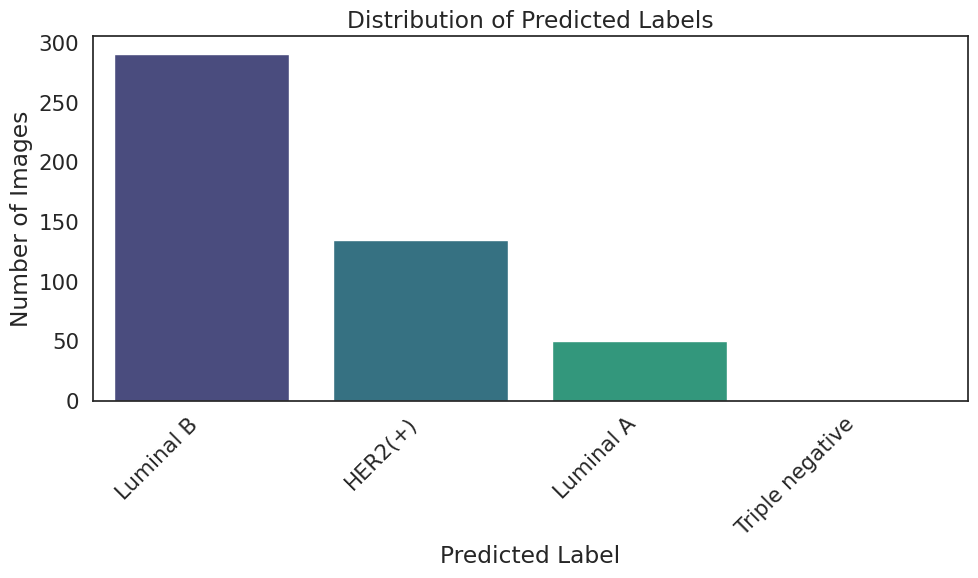

Predicted label distribution:
Luminal B          291
HER2(+)            135
Luminal A           50
Triple negative      1
Name: count, dtype: int64


In [ ]:
predicted_labels_series = pd.Series(all_image_predictions)

plt.figure(figsize=(10, 6))
sns.countplot(x=predicted_labels_series, palette='viridis', order=predicted_labels_series.value_counts().index)
plt.title('Distribution of Predicted Labels')
plt.xlabel('Predicted Label')
plt.ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Predicted label distribution:")
print(predicted_labels_series.value_counts())

In [ ]:
# Create the submission DataFrame
submission_df = pd.DataFrame({
    "sample_index": names,
    "label": all_image_predictions
})

# Sort the DataFrame by 'sample_index'
submission_df = submission_df.sort_values(by='sample_index').reset_index(drop=True)

# Save to CSV
submission_df.to_csv(experiment_name +".csv", index=False)

print("Submission file 'submission_patch_aggregated.csv' created successfully.")


Submission file 'submission_patch_aggregated.csv' created successfully.


In [ ]:
display(submission_df.head())

,sample_index,label
0,img_0000.png,Luminal B
1,img_0001.png,Luminal A
2,img_0002.png,Luminal A
3,img_0003.png,HER2(+)
4,img_0004.png,HER2(+)
